--- Physics Parameters ---
Input Viscosity : 14.8 cP
Calculated D    : 7.374061e-11 m^2/s
Echo Spacing    : 0.594560 s
Diff Penalty (K): 2.068328e+02 s^-1

--- Fit Results ---
T2 (Actual)     = 19.211093 s
T2 (Raw/Obs)    = 0.004834 s
R-squared       = 0.0789


C:\Users\Student\AppData\Local\Temp\ipykernel_12912\2717025473.py:108: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(decay_model, t_zeroed, v_data, p0=[A_guess, T2_guess, C_guess], maxfev=10000)


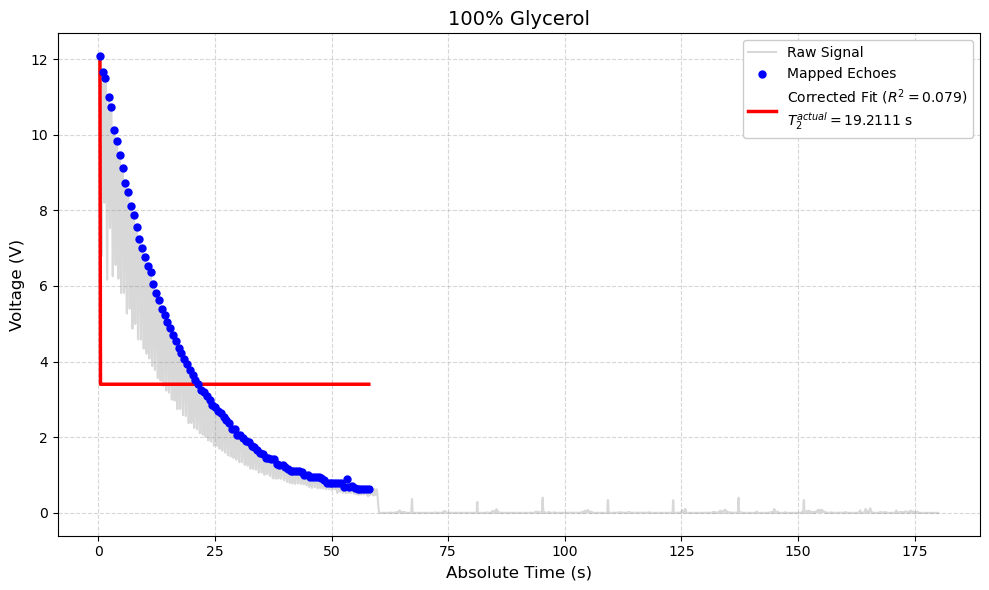

--- Physics Parameters ---
Input Viscosity : 21.3 cP
Calculated D    : 5.123761e-11 m^2/s
Echo Spacing    : 1.400320 s
Diff Penalty (K): 7.971954e+02 s^-1

--- Fit Results ---
T2 (Actual)     = 44.666026 s
T2 (Raw/Obs)    = 0.001254 s
R-squared       = 0.0710


C:\Users\Student\AppData\Local\Temp\ipykernel_12912\2717025473.py:108: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(decay_model, t_zeroed, v_data, p0=[A_guess, T2_guess, C_guess], maxfev=10000)


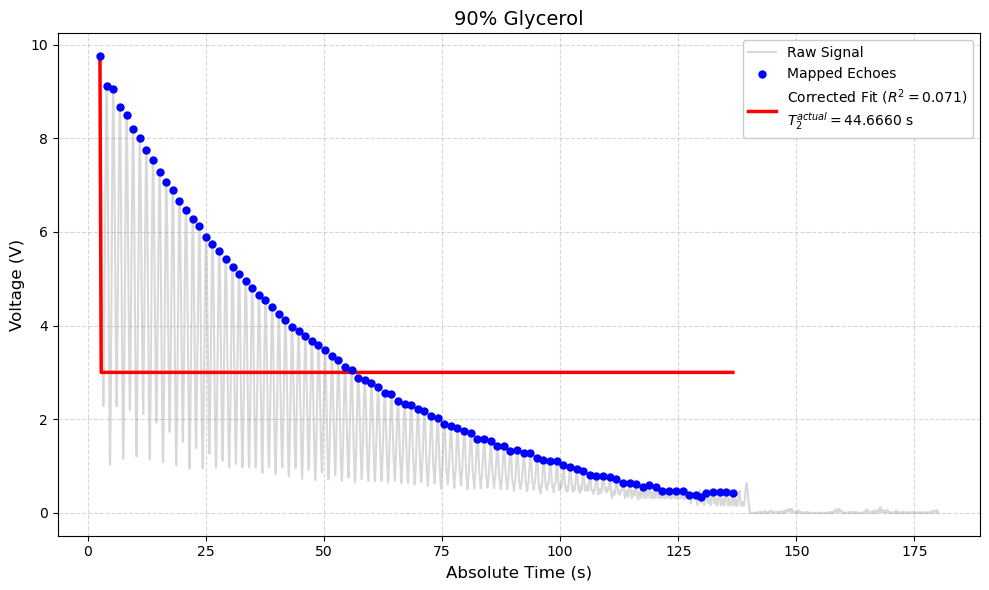

--- Physics Parameters ---
Input Viscosity : 35.5 cP
Calculated D    : 3.074256e-11 m^2/s
Echo Spacing    : 0.002335 s
Diff Penalty (K): 1.329631e-03 s^-1

--- Fit Results ---
T2 (Actual)     = 0.101721 s
T2 (Raw/Obs)    = 0.101707 s
R-squared       = 0.9748


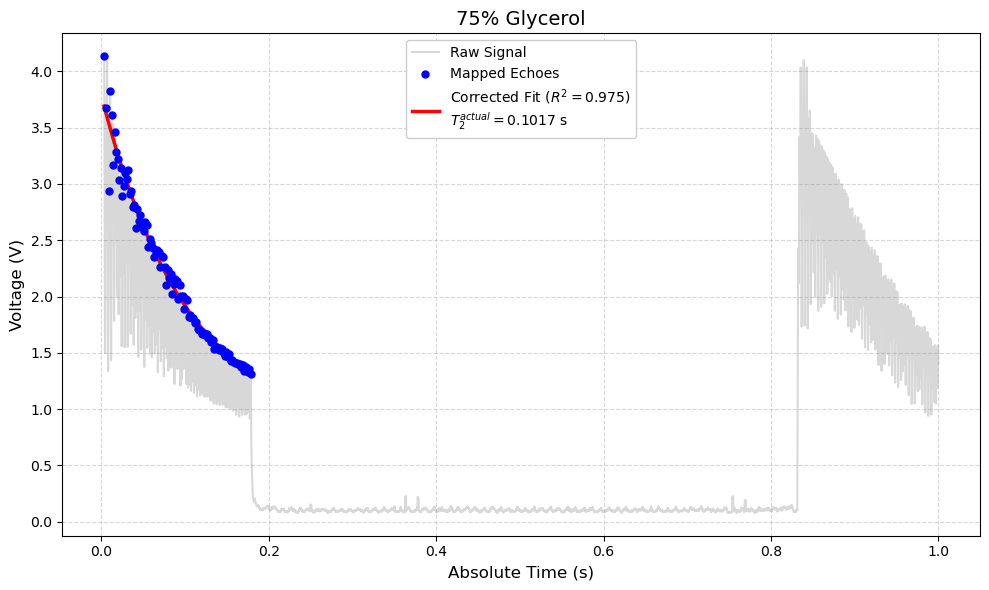

--- Physics Parameters ---
Input Viscosity : 142 cP
Calculated D    : 7.685641e-12 m^2/s
Echo Spacing    : 0.002335 s
Diff Penalty (K): 3.324077e-04 s^-1

--- Fit Results ---
T2 (Actual)     = 0.101710 s
T2 (Raw/Obs)    = 0.101707 s
R-squared       = 0.9748


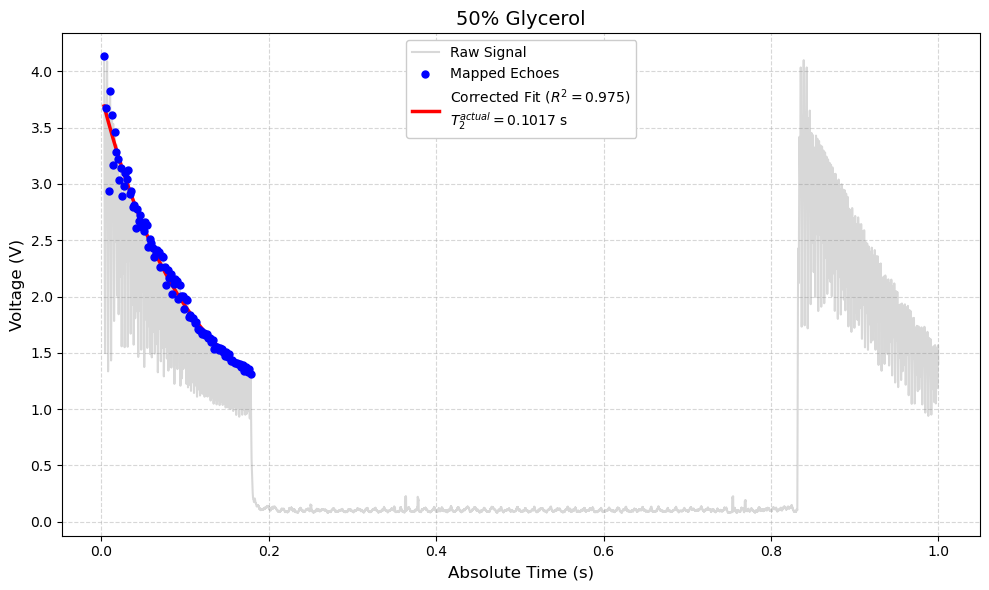

--- Physics Parameters ---
Input Viscosity : 934 cP
Calculated D    : 1.168481e-12 m^2/s
Echo Spacing    : 3.466240 s
Diff Penalty (K): 1.113936e+02 s^-1

--- Fit Results ---
T2 (Actual)     = 15.646720 s
T2 (Raw/Obs)    = 0.008972 s
R-squared       = 0.2542


C:\Users\Student\AppData\Local\Temp\ipykernel_12912\2717025473.py:108: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, _ = curve_fit(decay_model, t_zeroed, v_data, p0=[A_guess, T2_guess, C_guess], maxfev=10000)


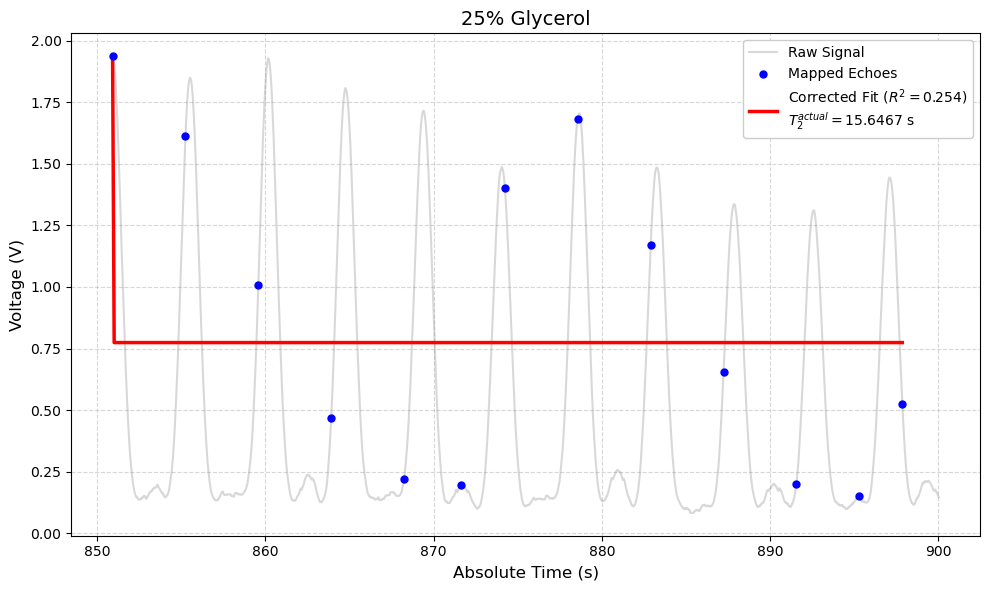

0

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

def analyze_t2_with_viscosity(file_path, plot_title, viscosity_cP, G=0.1, max_echoes=98, temp_K=298):
    """
    Analyzes T2 CPMG data using Viscosity to automatically calculate the Diffusion penalty.
    
    Parameters:
    - file_path: Path to the CSV.
    - plot_title: Title for the graph.
    - viscosity_cP: Viscosity of the sample in cP (centipoise or mPa*s).
    - G: Magnetic field gradient (T/m).
    - max_echoes: Number of peaks to map.
    - temp_K: Absolute temperature in Kelvin (default 298 K / 25 C).
    """
    # -----------------------------
    # 1. Calculate D from Viscosity (Stokes-Einstein)
    # -----------------------------
    k_B = 1.380649e-23  # Boltzmann constant (J/K)
    r = 2.0e-10         # Approx effective hydrodynamic radius (0.2 nm)
    
    # Convert viscosity from cP to SI units (Pa*s or kg/(m*s))
    eta_Pa_s = viscosity_cP * 1e-3
    
    # Calculate D
    D = (k_B * temp_K) / (6 * np.pi * eta_Pa_s * r)
    
    print("--- Physics Parameters ---")
    print(f"Input Viscosity : {viscosity_cP} cP")
    print(f"Calculated D    : {D:.6e} m^2/s")

    # -----------------------------
    # 2. Load & Clean Data
    # -----------------------------
    data = pd.read_csv(file_path, encoding='windows-1252', skiprows=1, usecols=[0, 1])
    data.columns = ['time', 'voltage']

    data['time'] = pd.to_numeric(data['time'], errors='coerce')
    data['voltage'] = pd.to_numeric(data['voltage'], errors='coerce')
    data = data.dropna(subset=['time', 'voltage']).reset_index(drop=True)

    vmaxid = data['voltage'].idxmax()
    t_start_analysis = data.loc[vmaxid, 'time']

    # -----------------------------
    # 3. Estimate Echo Spacing
    # -----------------------------
    post_peak_data = data.loc[vmaxid:].copy()
    min_prominence = post_peak_data['voltage'].max() * 0.05

    peaks_rough, _ = find_peaks(post_peak_data['voltage'], distance=20, prominence=min_prominence)
    t_peaks = post_peak_data.iloc[peaks_rough]['time'].values

    if len(t_peaks) > 5:
        period_guess = np.mean(np.diff(t_peaks[:5]))
    else:
        period_guess = np.mean(np.diff(t_peaks))

    print(f"Echo Spacing    : {period_guess:.6f} s")

    # -----------------------------
    # 4. Sequential windowed peak mapping
    # -----------------------------
    refined_times, refined_voltages = [], []
    window_half_width = period_guess * 0.25
    current_time_guess = t_start_analysis

    for i in range(max_echoes):
        t_start = current_time_guess - window_half_width
        t_end = current_time_guess + window_half_width
        
        window = data[(data['time'] >= t_start) & (data['time'] <= t_end)]
        if window.empty:
            break 
        
        max_idx = window['voltage'].idxmax()
        actual_max_t = window.loc[max_idx, 'time']
        actual_max_v = window.loc[max_idx, 'voltage']
        
        refined_times.append(actual_max_t)
        refined_voltages.append(actual_max_v)
        current_time_guess = actual_max_t + period_guess

    peak_results = pd.DataFrame({'Time': refined_times, 'Voltage': refined_voltages})

    # -----------------------------
    # 5. Diffusion-Corrected Fit
    # -----------------------------
    t_zeroed = (peak_results['Time'] - peak_results['Time'].iloc[0]).to_numpy()
    v_data = peak_results['Voltage'].to_numpy()

    gamma = 2 * np.pi * 15.53e6   # rad s^-1 T^-1
    tau = period_guess / 2
    K = gamma**2 * (G**2) * D * (tau**2) / 3
    print(f"Diff Penalty (K): {K:.6e} s^-1")

    def decay_model(t, A, T2_actual, C):
        if T2_actual <= 0: return np.inf
        return A * np.exp(-t * (1.0 / T2_actual + K)) + C

    A_guess = v_data.max() - v_data.min()
    T2_guess = t_zeroed[-1] / 3
    C_guess = v_data.min()

    popt, _ = curve_fit(decay_model, t_zeroed, v_data, p0=[A_guess, T2_guess, C_guess], maxfev=10000)
    A_fit, T2_actual_fit, C_fit = popt
    T2_observed = 1.0 / (1.0 / T2_actual_fit + K)

    residuals = v_data - decay_model(t_zeroed, *popt)
    r_sq = 1 - (np.sum(residuals**2) / np.sum((v_data - np.mean(v_data))**2))

    print("\n--- Fit Results ---")
    print(f"T2 (Actual)     = {T2_actual_fit:.6f} s")
    print(f"T2 (Raw/Obs)    = {T2_observed:.6f} s")
    print(f"R-squared       = {r_sq:.4f}")

    # -----------------------------
    # 6. Plotting
    # -----------------------------
    t_smooth = np.linspace(t_zeroed.min(), t_zeroed.max(), 500)
    v_smooth = decay_model(t_smooth, A_fit, T2_actual_fit, C_fit)
    t_smooth_absolute = t_smooth + peak_results['Time'].iloc[0]

    plt.figure(figsize=(10, 6))
    plt.plot(data.loc[vmaxid:, 'time'], data.loc[vmaxid:, 'voltage'], alpha=0.3, label='Raw Signal', color='gray')
    plt.scatter(peak_results['Time'], peak_results['Voltage'], s=25, color='blue', label='Mapped Echoes', zorder=5)
    
    fit_label = f'Corrected Fit ($R^2={r_sq:.3f}$)\n$T_2^{{actual}} = {T2_actual_fit:.4f}$ s'
    plt.plot(t_smooth_absolute, v_smooth, 'r-', linewidth=2.5, label=fit_label)

    plt.title(plot_title, fontsize=14)
    plt.xlabel('Absolute Time (s)', fontsize=12)
    plt.ylabel('Voltage (V)', fontsize=12)
    plt.legend(framealpha=1.0)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    
    return T2_actual_fit, T2_observed
analyze_t2_with_viscosity(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\100% glycerol\T_2 csv 1.csv", "100% Glycerol", viscosity_cP=14.8, max_echoes=97)
analyze_t2_with_viscosity(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\90% glycerol\T290.csv", "90% Glycerol", viscosity_cP=21.3, max_echoes=97)
analyze_t2_with_viscosity(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\50% glycerol\T2.csv", "75% Glycerol", viscosity_cP=35.5, max_echoes=97)
analyze_t2_with_viscosity(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\50% glycerol\T2.csv", "50% Glycerol", viscosity_cP=142, max_echoes=97)
analyze_t2_with_viscosity(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\25% Glyerol\T2.csv", "25% Glycerol", viscosity_cP=934, max_echoes=97)
